# Predicción del crimen - Modelo para predecir la ubicación del próximo crimen

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Data exploratory (Explorar datos)

In [2]:
cluster = pd.read_csv("cluster_location-co.csv")

crime = pd.read_csv('crime-colombia.csv', header=0)
print(crime.head())

         City  crimeCluster  Murder  Assault  CaseResolved  Kidnapping
0      Bogota             4    13.2      236            58        21.2
1    Medellin             4    10.0      263            48        44.5
2  El Encanto             4     8.1      294            80        31.0
3     Caceres             3     8.8      190            50        19.5
4     Cordoba             4     9.0      276            91        40.6


In [3]:
def stateToNumber(s):
    l = 0
    for x in s:
        l = l + int(hex(ord(x)),16)
    return l

xref = pd.DataFrame(crime['City'])
crime['City']=crime['City'].apply(lambda x: stateToNumber(x))
crime.head()

,City,crimeCluster,Murder,Assault,CaseResolved,Kidnapping
0,604,4,13.2,236,58,21.2
1,810,4,10.0,263,48,44.5
2,921,4,8.1,294,80,31.0
3,694,3,8.8,190,50,19.5
4,698,4,9.0,276,91,40.6


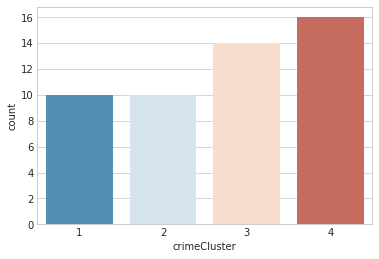

In [4]:
%matplotlib inline

sns.set_style('whitegrid')
sns.countplot(x='crimeCluster',data=crime,palette='RdBu_r')

## 2. Model Training (Entrenamiento modelo)

In [5]:
from sagemaker import KMeans
from sagemaker import get_execution_role

role = get_execution_role()
print(role)

bucket = "alexbc.datalake"

data_location = 's3://{}/kidnapping-records/model/data'.format(bucket)
output_location = 's3://{}/kidnapping-records/model/output'.format(bucket)

print('training data will be uploaded to: {}'.format(data_location))
print('training artifacts will be uploaded to: {}'.format(output_location))

kmeans = KMeans(role=role,
                train_instance_count=1,
                train_instance_type='ml.m4.xlarge',
                output_path=output_location,
                k=10,
                data_location=data_location)

arn:aws:iam::771620814942:role/service-role/AmazonSageMaker-ExecutionRole-20171212T090635
training data will be uploaded to: s3://alexbc.datalake/kidnapping-records/model/data
training artifacts will be uploaded to: s3://alexbc.datalake/kidnapping-records/model/output


In [6]:
crimeArray = crime.as_matrix().astype(np.float32)
crimeArray.shape
slice=crimeArray[:,1:5]

In [7]:
%%time
kmeans.fit(kmeans.record_set(slice))

INFO:sagemaker:Creating training-job with name: kmeans-2019-02-12-21-07-19-443


2019-02-12 21:07:19 Starting - Starting the training job...
2019-02-12 21:07:20 Starting - Launching requested ML instances......
2019-02-12 21:08:26 Starting - Preparing the instances for training......
2019-02-12 21:09:41 Downloading - Downloading input data...
2019-02-12 21:10:16 Training - Downloading the training image..
Docker entrypoint called with argument(s): train
[02/12/2019 21:10:23 INFO 140088968582976] Reading default configuration from /opt/amazon/lib/python2.7/site-packages/algorithm/resources/default-input.json: {u'_tuning_objective_metric': u'', u'_num_gpus': u'auto', u'local_lloyd_num_trials': u'auto', u'_log_level': u'info', u'_kvstore': u'auto', u'local_lloyd_init_method': u'kmeans++', u'force_dense': u'true', u'epochs': u'1', u'init_method': u'random', u'local_lloyd_tol': u'0.0001', u'local_lloyd_max_iter': u'300', u'_disable_wait_to_read': u'false', u'extra_center_factor': u'auto', u'eval_metrics': u'["msd"]', u'_num_kv_servers': u'1', u'mini_batch_size': u'5000'


2019-02-12 21:10:34 Uploading - Uploading generated training model
2019-02-12 21:10:34 Completed - Training job completed
Billable seconds: 53
CPU times: user 619 ms, sys: 31 ms, total: 650 ms
Wall time: 3min 42s


## 3. Model Deployment - (Mover el modelo a la producción).

In [8]:
%%time
kmeans_predictor = kmeans.deploy(initial_instance_count=1,
                                 instance_type='ml.m5.xlarge')

INFO:sagemaker:Creating model with name: kmeans-2019-02-12-21-11-01-378
INFO:sagemaker:Creating endpoint with name kmeans-2019-02-12-21-07-19-443


---------------------------------------------------------------!CPU times: user 353 ms, sys: 30.5 ms, total: 383 ms
Wall time: 5min 19s


## 4. Inference

In [9]:
!pip install git+https://github.com/psychemedia/ipython_magic_folium.git
%load_ext folium_magic

  Cloning https://github.com/psychemedia/ipython_magic_folium.git to /tmp/pip-req-build-EmPqw6
  Running setup.py bdist_wheel for ipython-magic-folium ... done
  Stored in directory: /tmp/pip-ephem-wheel-cache-q8Bfoa/wheels/7c/49/f8/8577b6d1b8fcaa766dd7c6f7996f22a913e4a260443e75a095
Successfully built ipython-magic-folium
You are using pip version 10.0.1, however version 19.0.1 is available.
You should consider upgrading via the 'pip install --upgrade pip' command.


In [10]:
slice=crimeArray[:,1:5]
slice.shape
slice

s=slice[2:3]

result = kmeans_predictor.predict(s)
clusters = [r.label['closest_cluster'].float32_tensor.values[0] for r in result]
i = 0
    
for r in result:
    out = {
      "City" : xref['City'].iloc[i],
      "closest_cluster" :  r.label['closest_cluster'].float32_tensor.values[0],
      "crimeCluster" : crime['crimeCluster'].iloc[i],  
      "Kidnapping" :  crime['Kidnapping'].iloc[i],
      "Latitude"   :  cluster['lat'][r.label['closest_cluster'].float32_tensor.values[0]],
      "Longitude"  :  cluster['long'][r.label['closest_cluster'].float32_tensor.values[0]]
    }    
    print(out) 
    i = i + 1

{'City': 'Bogota', 'Kidnapping': 21.2, 'crimeCluster': 4, 'Longitude': -74.07380461692809, 'closest_cluster': 3.0, 'Latitude': 4.598915389484102}


In [12]:
# Set marker
marker = [[4.600851053970031,-74.07008171081543,'Operacion de equipo mas cercano!'],[
    cluster['lat'][r.label['closest_cluster'].float32_tensor.values[0]],
    cluster['long'][r.label['closest_cluster'].float32_tensor.values[0]],'Proxima area para un crimen!']]

#marker = [[4.600851053970031,-74.07008171081543,'Operacion de equipo mas cercano!'],[
#           4.598915389484102,-74.0738046169281,'Proxima area para un crimen!']]

%folium_map -l 4.60089383102632,-74.07192707061768 -z 17 -M marker -g location-bogota.json

# 99. Other examples

https://aws.amazon.com/blogs/publicsector/estimating-hurricane-wind-speeds-with-machine-learning/